# Analiza deformacji bez wpływu kopalni Turów

Notatnik powtarza analizę z `EGMS_analysis_pipeline.ipynb` (Isolation Forest + K-means) na danych, z których **usunięto punkty PS odkrywki i zwałowiska**.

W wariancie pełnym ok. 89% anomalii i dwa z czterech klastrów (ok. −31 mm/rok) to punkty kopalni. Kopalnia dominuje rozkład cech: wyznacza próg anomalii, skalę standaryzacji i podział na klastry. Przez to subtelniejsze zjawiska poza kopalnią giną w tle. Po wymaskowaniu kopalni model porównuje punkty tylko z otoczeniem, które nie jest bezpośrednio przekształcane przez górnictwo.

**Dane wejściowe:**

- `EGMS_Turow_U.csv` – wszystkie PS (6268), szeregi bez zim,
- `EGMS_Turow_bez_kopalni_U.csv` – wybór punktów z QGIS (**uwaga: mimo nazwy plik zawiera punkty *w obrębie* odkrywki, a nie poza nią** – używamy go jako maski kopalni),
- `EGMS_Turow_U_results.csv` – wyniki wariantu pełnego (do porównania).

**Wynik:** `EGMS_Turow_bez_kopalni_U_results.csv` – ten sam układ kolumn co `EGMS_Turow_U_results.csv`.

Bezpośredni wpływ kopalni usuwamy w dwóch krokach:

1. usuwamy punkty odkrywki (maska z QGIS),
2. usuwamy pozostałe zwarte strefy bardzo szybkiego osiadania przy kopalni (zwałowisko zewnętrzne, krawędź odkrywki).

Pośredni wpływ kopalni (np. osiadanie wywołane odwodnieniem) **zostaje w danych** – to właśnie ten sygnał chcemy zobaczyć wyraźniej.

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# ETAP 1 — Dane i maska kopalni

## Wszystkie PS

In [2]:
df_all = pd.read_csv("EGMS_Turow_U.csv")

date_cols = [
    col for col in df_all.columns
    if str(col).isdigit() and len(str(col)) == 8
]
dates = pd.to_datetime(date_cols, format="%Y%m%d")

print("Liczba PS:", len(df_all))
print("Liczba dat:", len(date_cols), f"({dates.min().date()} – {dates.max().date()})")

Liczba PS: 6268
Liczba dat: 239 (2020-03-08 – 2024-12-06)


## Maska odkrywki

Plik z QGIS ma surowy układ EGMS: punkty dwóch kafli są zapisane obok siebie (kolumny `pid` i `pid_2`), a szereg zawiera daty zimowe. Bierzemy z niego tylko identyfikatory punktów – szeregi czasowe pozostają z `EGMS_Turow_U.csv` (te same daty co w wariancie pełnym).

In [3]:
mask_raw = pd.read_csv("EGMS_Turow_bez_kopalni_U.csv", low_memory=False)

pid_odkrywka = set(mask_raw["pid"].dropna()) | set(mask_raw["pid_2"].dropna())

df_all["odkrywka"] = df_all["pid"].isin(pid_odkrywka)

print("PS w pliku maski:", len(pid_odkrywka))
print("…z tego obecnych w EGMS_Turow_U.csv:", df_all["odkrywka"].sum())
print()
print("Mediana mean_velocity w masce:", df_all.loc[df_all["odkrywka"], "mean_velocity"].median(), "mm/rok")
print("Mediana mean_velocity poza maską:", df_all.loc[~df_all["odkrywka"], "mean_velocity"].median(), "mm/rok")

PS w pliku maski: 858
…z tego obecnych w EGMS_Turow_U.csv: 858

Mediana mean_velocity w masce: -11.1 mm/rok
Mediana mean_velocity poza maską: -0.8 mm/rok


Punkty z pliku mają medianę prędkości ok. −11 mm/rok i leżą w zwartym obszarze ok. 6 × 6 km – jest to odkrywka. Punkty poza maską mają medianę ok. −1 mm/rok.

## Czy przy krawędzi odkrywki trzeba dodać bufor?

Obrys maski tworzymy z komórek siatki EGMS L3 (kwadraty 100 × 100 m wokół punktów maski). Dla pozostałych PS liczymy odległość od tego obrysu i sprawdzamy, czy prędkości przy krawędzi odbiegają od dalszego otoczenia.

In [4]:
gdf_all = gpd.GeoDataFrame(
    df_all,
    geometry=gpd.points_from_xy(df_all["easting"], df_all["northing"]),
    crs="EPSG:3035"
)

# Komórki 100 x 100 m wokół punktów maski
obrys_odkrywki = gdf_all[gdf_all["odkrywka"]].buffer(50, cap_style="square").union_all()

poza = gdf_all[~gdf_all["odkrywka"]].copy()
poza["odl_od_odkrywki"] = poza.distance(obrys_odkrywki)

przedzialy = [0, 100, 200, 300, 500, 1000, 2000, 3000, 5000, 25000]
poza["przedzial"] = pd.cut(poza["odl_od_odkrywki"], przedzialy, include_lowest=True)

poza.groupby("przedzial", observed=True).agg(
    n_PS=("pid", "count"),
    mediana_velocity=("mean_velocity", "median"),
    percentyl_10=("mean_velocity", lambda s: s.quantile(0.1)),
).round(2)

,n_PS,mediana_velocity,percentyl_10
przedzial,,,
"(-0.001, 100.0]",26,-2.20,-4.20
"(100.0, 200.0]",24,-1.10,-3.66
"(200.0, 300.0]",58,-1.20,-5.18
"(300.0, 500.0]",110,-1.65,-6.60
"(500.0, 1000.0]",380,-0.90,-4.50
"(1000.0, 2000.0]",809,-0.60,-3.30
"(2000.0, 3000.0]",644,-1.70,-6.80
"(3000.0, 5000.0]",1747,-2.00,-6.84
"(5000.0, 25000.0]",1612,-0.40,-1.20


Mediana prędkości tuż przy krawędzi (do 100 m) jest tylko nieznacznie niższa niż dalej, a od 100 m nie różni się od reszty obszaru. Szeroki bufor wokół całej odkrywki usunąłby więc głównie zwykłe punkty. Zamiast tego usuwamy tylko konkretne strefy, w których szybkie osiadanie faktycznie występuje.

## Pozostałe strefy szybkiego osiadania

Szukamy poza maską zwartych stref, w których PS osiadają szybciej niż **10 mm/rok**. Taka prędkość jest kilkukrotnie wyższa niż w terenie poza kopalnią (75% PS poza maską ma prędkość powyżej ok. −3 mm/rok).

Punkty szybsze niż 10 mm/rok łączymy w strefy, jeżeli leżą nie dalej niż **300 m** od siebie (łączenie pojedyncze – `DBSCAN` z `min_samples=1`). Na zwałowisku pokrycie PS jest nieregularne, więc samo sąsiedztwo komórek siatki dzieliłoby je na wiele kawałków. Za strefę kopalni uznajemy strefy z co najmniej **10 PS**. Wynik praktycznie nie zależy od odległości łączenia (przy 300, 500 i 700 m wykrywane są te same dwie strefy).

Pojedyncze szybkie punkty i małe skupiska zostają w danych – mogą to być lokalne anomalie, które chcemy wykryć.

In [5]:
PROG_VELOCITY = -10   # [mm/rok]
ODL_LACZENIA = 300    # [m]
MIN_PS_STREFY = 10
BUFOR_STREFY = 300    # [m]

szybkie = poza[poza["mean_velocity"] < PROG_VELOCITY].copy()

szybkie["strefa"] = DBSCAN(eps=ODL_LACZENIA, min_samples=1).fit_predict(
    szybkie[["easting", "northing"]]
)

strefy = szybkie.groupby("strefa").agg(
    n_PS=("pid", "count"),
    mediana_velocity=("mean_velocity", "median"),
    easting=("easting", "mean"),
    northing=("northing", "mean"),
    odl_od_odkrywki=("odl_od_odkrywki", "min"),
)
strefy = strefy[strefy["n_PS"] >= MIN_PS_STREFY].sort_values("n_PS", ascending=False)
strefy.round(0)

,n_PS,mediana_velocity,easting,northing,odl_od_odkrywki
strefa,,,,,
2,144,-36.0,4670260.0,3104636.0,2264.0
0,13,-14.0,4667888.0,3101735.0,158.0


Wykryto dwie strefy:

- ok. 145 PS w obszarze 2,5–5 km na północny wschód od maski, na północ od Bogatyni (ok. 50,94° N, 14,97° E), z medianą prędkości ok. −35 mm/rok – **najpewniej zwałowisko zewnętrzne KWB Turów**. Warto to potwierdzić na podkładzie w QGIS i ewentualnie zastąpić tę część maski obrysem zwałowiska,
- 13 PS tuż przy krawędzi odkrywki (ok. 150 m od maski) – punkty skarpy, których nie objęła maska.

Każdą strefę maskujemy jako obrys wypukły jej punktów powiększony o bufor 300 m, żeby objąć też rozproszone, wolniej osiadające punkty na jej obrzeżu.

In [6]:
obrysy_stref = (
    szybkie[szybkie["strefa"].isin(strefy.index)]
    .dissolve(by="strefa")
    .convex_hull
    .buffer(BUFOR_STREFY)
)
obrys_stref = obrysy_stref.union_all()

df_all["strefa_kopalni"] = (
    ~df_all["odkrywka"]
    & gdf_all.within(obrys_stref).to_numpy()
)
df_all["kopalnia"] = df_all["odkrywka"] | df_all["strefa_kopalni"]

print("PS odkrywki (maska z QGIS):", df_all["odkrywka"].sum())
print("PS w strefach przy kopalni:", df_all["strefa_kopalni"].sum())
print("  …z tego szybciej niż 10 mm/rok:", (df_all["strefa_kopalni"] & (df_all["mean_velocity"] < PROG_VELOCITY)).sum())
print("Razem usunięte:", df_all["kopalnia"].sum())
print("Pozostałe PS:", (~df_all["kopalnia"]).sum())

PS odkrywki (maska z QGIS): 858
PS w strefach przy kopalni: 225
  …z tego szybciej niż 10 mm/rok: 158
Razem usunięte: 1083
Pozostałe PS: 5185


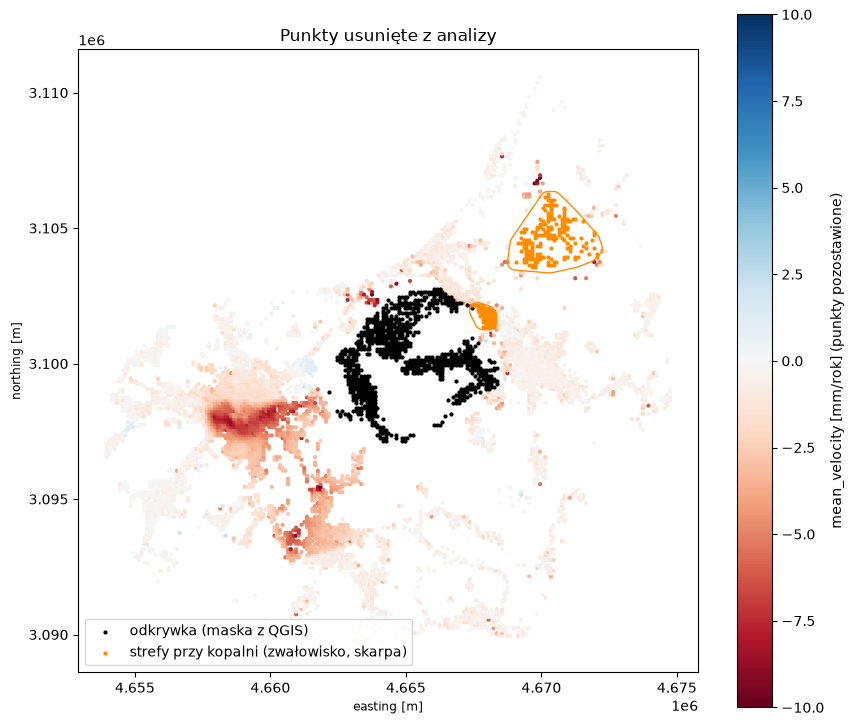

In [7]:
fig, ax = plt.subplots(figsize=(10, 9))

pozostale = df_all[~df_all["kopalnia"]]
sc = ax.scatter(
    pozostale["easting"], pozostale["northing"],
    c=pozostale["mean_velocity"], cmap="RdBu", vmin=-10, vmax=10, s=4
)
for kolumna, kolor, opis in [
    ("odkrywka", "black", "odkrywka (maska z QGIS)"),
    ("strefa_kopalni", "darkorange", "strefy przy kopalni (zwałowisko, skarpa)"),
]:
    sel = df_all[df_all[kolumna]]
    ax.scatter(sel["easting"], sel["northing"], s=4, color=kolor, label=opis)

gpd.GeoSeries(obrysy_stref).boundary.plot(ax=ax, color="darkorange", linewidth=1)

plt.colorbar(sc, ax=ax, label="mean_velocity [mm/rok] (punkty pozostawione)")
ax.set_aspect("equal")
ax.set_xlabel("easting [m]")
ax.set_ylabel("northing [m]")
ax.set_title("Punkty usunięte z analizy")
ax.legend(loc="lower left")
plt.show()

## Zbiór do analizy

In [8]:
df = df_all[~df_all["kopalnia"]].drop(columns=["odkrywka", "strefa_kopalni", "kopalnia"]).reset_index(drop=True)

basic_features = ["mean_velocity", "acceleration", "seasonality", "rmse_ts"]

porownanie = pd.concat(
    {
        "pełny": df_all[basic_features].describe().T[["mean", "std", "50%", "min", "max"]],
        "bez kopalni": df[basic_features].describe().T[["mean", "std", "50%", "min", "max"]],
    },
    axis=1
)

print("Liczba PS:", len(df))
porownanie.round(2)

Liczba PS: 5185


pełny                         bez kopalni                    \
               mean   std   50%   min   max        mean   std   50%   min   
mean_velocity -4.42  9.80 -1.00 -75.3  10.2       -1.52  1.83 -0.70 -20.8   
acceleration   0.03  0.54 -0.03  -2.3   3.6       -0.07  0.36 -0.05  -2.3   
seasonality    1.12  1.14  0.70   0.0   8.9        0.80  0.58  0.70   0.0   
rmse_ts        1.36  0.76  1.10   0.4   4.7        1.21  0.66  0.90   0.4   

                     
                max  
mean_velocity  2.40  
acceleration   2.61  
seasonality    5.10  
rmse_ts        3.90

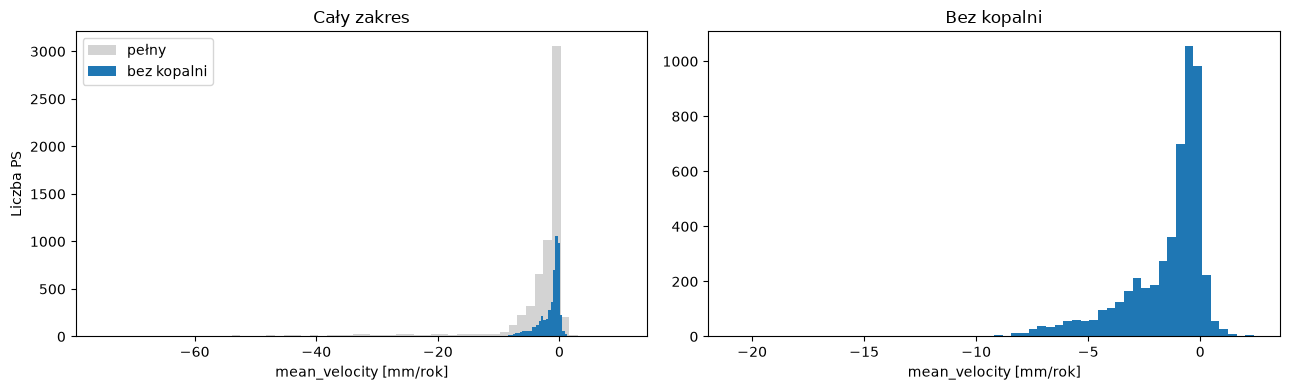

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df_all["mean_velocity"], bins=60, color="lightgrey", label="pełny")
axes[0].hist(df["mean_velocity"], bins=60, label="bez kopalni")
axes[0].set_xlabel("mean_velocity [mm/rok]")
axes[0].set_ylabel("Liczba PS")
axes[0].set_title("Cały zakres")
axes[0].legend()

axes[1].hist(df["mean_velocity"], bins=60)
axes[1].set_xlabel("mean_velocity [mm/rok]")
axes[1].set_title("Bez kopalni")

plt.tight_layout()
plt.show()

# ETAP 2 — Cechy szeregu czasowego

Cechy liczymy tak samo jak w `EGMS_analysis_pipeline.ipynb`: trend całego okresu, trendy roczne oraz trend ostatnich 12 miesięcy względem okresu wcześniejszego.

Zamiast dopasowywać `LinearRegression` osobno dla każdego PS, nachylenie liczymy wzorem najmniejszych kwadratów dla wszystkich punktów naraz (`slope = cov(t, y) / var(t)`, `R² = corr(t, y)²`). Wynik jest identyczny (sprawdzamy to niżej), a obliczenia trwają ułamek sekundy zamiast ok. 2 minut. Szeregi nie mają braków danych, więc nie trzeba ich maskować.

In [10]:
time_years = ((dates - dates.min()).days / 365.25).to_numpy()
Y = df[date_cols].to_numpy(dtype=float)

assert not np.isnan(Y).any(), "Szeregi zawierają braki danych"


def fit_linear_trend_all(Y, t):
    # Nachylenie [mm/rok] i R² trendu liniowego dla każdego wiersza macierzy Y
    t_c = t - t.mean()
    Y_c = Y - Y.mean(axis=1, keepdims=True)

    slope = (Y_c @ t_c) / (t_c @ t_c)

    ss_tot = (Y_c ** 2).sum(axis=1)
    r2 = np.full(len(Y), np.nan)
    np.divide(slope ** 2 * (t_c @ t_c), ss_tot, out=r2, where=ss_tot > 0)

    return slope, r2


def czas_od_poczatku(d):
    return ((d - d.min()).days / 365.25).to_numpy()

In [11]:
# 2A. Trend całego okresu
df["trend"], df["trend_R2"] = fit_linear_trend_all(Y, time_years)

print("Korelacja trend vs mean_velocity:", round(df["trend"].corr(df["mean_velocity"]), 3))

Korelacja trend vs mean_velocity: 0.999


In [12]:
# 2B. Trendy w kolejnych latach
years = sorted(pd.Index(dates.year).unique())
yearly_trend_cols = []

for year in years:
    mask = (dates.year == year)
    col_name = f"trend_{year}"
    yearly_trend_cols.append(col_name)

    df[col_name], _ = fit_linear_trend_all(Y[:, mask], czas_od_poczatku(dates[mask]))

df["annual_trend_std"] = df[yearly_trend_cols].std(axis=1)

df[["pid"] + yearly_trend_cols + ["annual_trend_std"]].head()

,pid,trend_2020,trend_2021,trend_2022,trend_2023,trend_2024,annual_trend_std
0,20bo4cXUMl,0.063981,-1.181882,0.920196,0.064430,-1.701046,1.057410
1,20bo4cXUMm,-1.000710,-0.895085,0.956541,-1.879380,-0.931802,1.037393
2,20bo4cXUMn,-0.846038,-0.330081,1.615051,0.679656,-1.121016,1.134871
3,20bo4cXUMo,-0.198776,-2.087870,-0.956211,-1.137607,-0.084846,0.810340
4,20bo4cXUMp,-1.338008,-0.163884,-1.037492,-0.222697,-2.467662,0.943719


In [13]:
# 2C. Ostatnie 12 miesięcy względem wcześniejszego okresu
recent_start = dates.max() - pd.DateOffset(years=1)

baseline_mask = (dates < recent_start)
recent_mask = (dates >= recent_start)

df["baseline_velocity"], _ = fit_linear_trend_all(Y[:, baseline_mask], czas_od_poczatku(dates[baseline_mask]))
df["recent_velocity"], _ = fit_linear_trend_all(Y[:, recent_mask], czas_od_poczatku(dates[recent_mask]))

df["trend_change"] = df["recent_velocity"] - df["baseline_velocity"]

print("Okres bazowy:", dates[baseline_mask].min().date(), "–", dates[baseline_mask].max().date())
print("Okres ostatni:", dates[recent_mask].min().date(), "–", dates[recent_mask].max().date())

Okres bazowy: 2020-03-08 – 2023-11-30
Okres ostatni: 2023-12-06 – 2024-12-06


Kontrola: dla PS obecnych w obu wariantach cechy muszą być takie same jak w `EGMS_Turow_U_results.csv` – zmienia się tylko zbiór punktów, a nie sposób liczenia cech.

In [14]:
wyniki_pelne = pd.read_csv("EGMS_Turow_U_results.csv")

kontrola = df[["pid", "trend", "trend_R2", "trend_change"]].merge(
    wyniki_pelne[["pid", "trend", "trend_R2", "trend_change"]], on="pid", suffixes=("", "_pelny")
)

for cecha in ["trend", "trend_R2", "trend_change"]:
    roznica = (kontrola[cecha] - kontrola[f"{cecha}_pelny"]).abs().max()
    print(f"Maks. różnica {cecha}: {roznica:.1e}")

Maks. różnica trend: 1.4e-14
Maks. różnica trend_R2: 2.8e-15
Maks. różnica trend_change: 1.1e-14


# ETAP 3 — Wybór cech

Ten sam zestaw cech co w wariancie pełnym, żeby różnice wynikały wyłącznie z usunięcia kopalni.

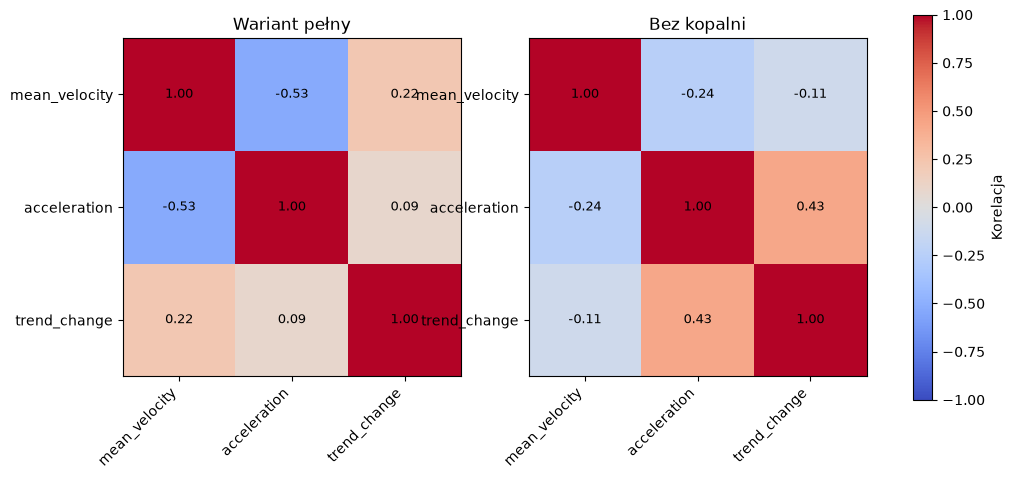

In [15]:
model_features = ["mean_velocity", "acceleration", "trend_change"]
control_features = ["rmse_ts", "trend_R2", "seasonality"]

corr_pelny = wyniki_pelne[model_features].corr()
corr_bk = df[model_features].corr()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, corr, tytul in [(axes[0], corr_pelny, "Wariant pełny"), (axes[1], corr_bk, "Bez kopalni")]:
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(model_features)), model_features, rotation=45, ha="right")
    ax.set_yticks(range(len(model_features)), model_features)
    for i in range(len(model_features)):
        for j in range(len(model_features)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title(tytul)

plt.colorbar(im, ax=axes, label="Korelacja")
plt.show()

# ETAP 4 — Isolation Forest

Te same parametry co w wariancie pełnym. Próg anomalii (5% najwyższych `anomaly_score`) liczymy na nowo – jest teraz wyznaczany względem otoczenia kopalni, a nie względem samej kopalni.

In [16]:
X_if = df[model_features].copy()

iso_forest = IsolationForest(
    n_estimators=300,
    contamination="auto",
    random_state=42
)
iso_forest.fit(X_if)

# Odwrócenie znaku: wyższy wynik oznacza bardziej nietypowy PS
df["anomaly_score"] = -iso_forest.score_samples(X_if)

threshold = df["anomaly_score"].quantile(0.95)
df["anomaly"] = df["anomaly_score"] >= threshold

print("Próg anomaly_score:", round(threshold, 3))
print(df["anomaly"].value_counts())

Próg anomaly_score: 0.567
anomaly
False    4925
True      260
Name: count, dtype: int64


## Kontrola wyniku

Te same pytania kontrolne co w wariancie pełnym:

1. Czy `anomaly_score` jest związany z RMSE szeregu?
2. Jak wyglądają szeregi punktów o najwyższym wyniku?
3. Czy model wskazuje wyłącznie PS o najbardziej ujemnym `mean_velocity`?

Korelacja anomaly_score vs RMSE: 0.47
Korelacja anomaly_score vs RMSE (wariant pełny): 0.621


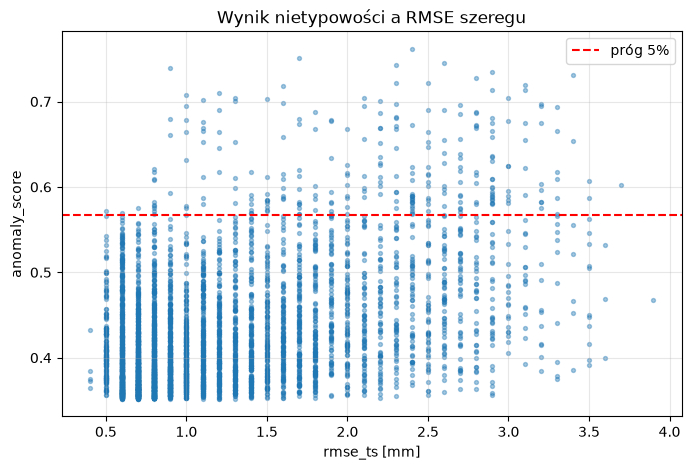

In [17]:
print("Korelacja anomaly_score vs RMSE:", round(df["anomaly_score"].corr(df["rmse_ts"]), 3))
print("Korelacja anomaly_score vs RMSE (wariant pełny):",
      round(wyniki_pelne["anomaly_score"].corr(wyniki_pelne["rmse_ts"]), 3))

plt.figure(figsize=(8, 5))
plt.scatter(df["rmse_ts"], df["anomaly_score"], alpha=0.4, s=8)
plt.axhline(threshold, color="red", linestyle="--", label="próg 5%")
plt.xlabel("rmse_ts [mm]")
plt.ylabel("anomaly_score")
plt.title("Wynik nietypowości a RMSE szeregu")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

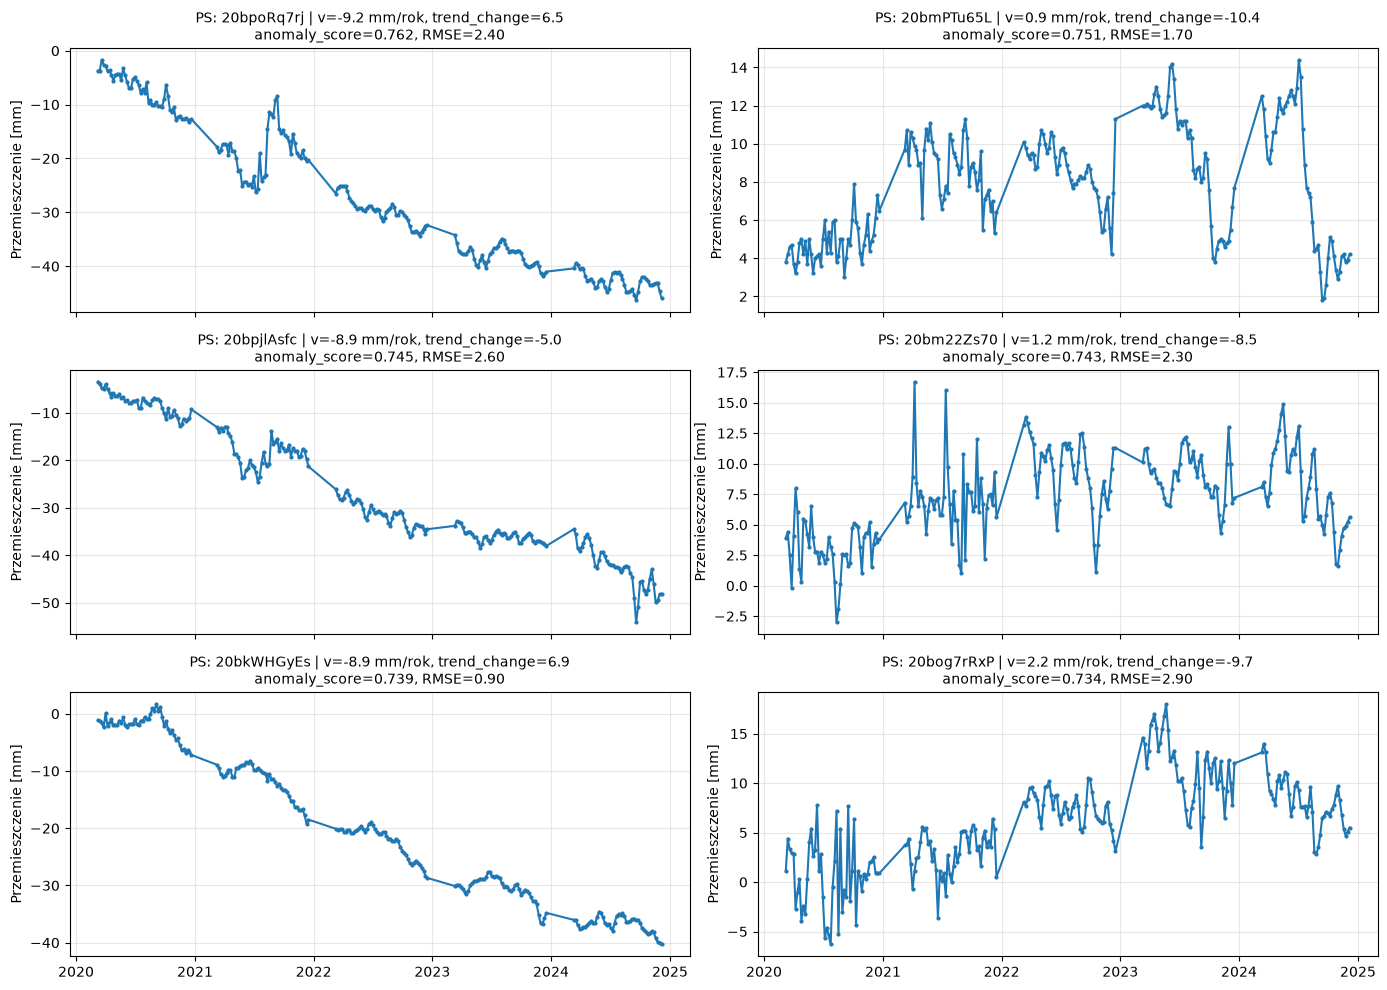

In [18]:
top_anomalies = df.nlargest(6, "anomaly_score")

fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True)

for ax, (_, row) in zip(axes.flatten(), top_anomalies.iterrows()):
    ax.plot(dates, row[date_cols].astype(float).values, marker="o", markersize=2)
    ax.set_title(
        f"PS: {row['pid']} | v={row['mean_velocity']:.1f} mm/rok, "
        f"trend_change={row['trend_change']:.1f}\n"
        f"anomaly_score={row['anomaly_score']:.3f}, RMSE={row['rmse_ts']:.2f}",
        fontsize=10
    )
    ax.set_ylabel("Przemieszczenie [mm]")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
top20_model = set(df.nlargest(20, "anomaly_score")["pid"])
top20_velocity = set(df.nsmallest(20, "mean_velocity")["pid"])

print("Wspólne PS w TOP20:", len(top20_model & top20_velocity), "/ 20")

Wspólne PS w TOP20: 6 / 20


# ETAP 5 — K-means

Standaryzację i dobór `k` wykonujemy od nowa. W wariancie pełnym średnie i odchylenia cech były silnie zawyżone przez kopalnię (np. odchylenie `mean_velocity` ok. 10 mm/rok), więc po standaryzacji różnice między punktami poza kopalnią były „ściśnięte”.

In [20]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[model_features])

print("Średnie cech:", dict(zip(model_features, scaler.mean_.round(2))))
print("Odchylenia cech:", dict(zip(model_features, scaler.scale_.round(2))))

Średnie cech: {'mean_velocity': np.float64(-1.52), 'acceleration': np.float64(-0.07), 'trend_change': np.float64(0.03)}
Odchylenia cech: {'mean_velocity': np.float64(1.83), 'acceleration': np.float64(0.36), 'trend_change': np.float64(2.1)}


In [21]:
ks = range(2, 9)
results_k = []

for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = km.fit_predict(X_scaled)
    results_k.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
        "najmniejszy_klaster": np.bincount(labels).min(),
    })

results_k = pd.DataFrame(results_k)
results_k["spadek_inertii_%"] = -results_k["inertia"].pct_change() * 100
results_k.round(3)

,k,inertia,silhouette,najmniejszy_klaster,spadek_inertii_%
0,2,11189.476,0.368,1353,NaN
1,3,8471.747,0.312,1036,24.288
2,4,7148.991,0.327,678,15.614
3,5,6352.386,0.253,370,11.143
4,6,5776.845,0.249,202,9.060
5,7,5246.819,0.246,145,9.175
6,8,4762.169,0.266,141,9.237


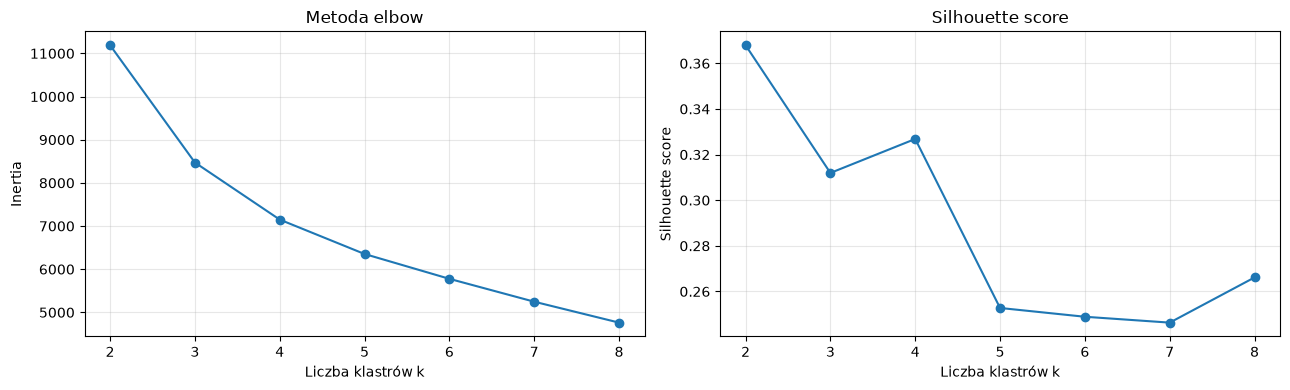

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(results_k["k"], results_k["inertia"], marker="o")
axes[0].set_xlabel("Liczba klastrów k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Metoda elbow")
axes[0].grid(alpha=0.3)

axes[1].plot(results_k["k"], results_k["silhouette"], marker="o")
axes[1].set_xlabel("Liczba klastrów k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette score")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Wybór `k`

Spadek inercji maleje z ok. 24% (`k = 2 → 3`) i 16% (`3 → 4`) do ok. 11% (`4 → 5`), a od `k = 5` utrzymuje się na stałym poziomie ok. 9%. Silhouette jest najwyższy dla `k = 2` (0,37), dla `k = 4` niewiele niższy (0,33), a od `k = 5` spada do ok. 0,25.

`k = 2` oddziela jedynie punkty osiadające (mediana ok. −3,6 mm/rok) od pozostałych. Przyjmujemy **`k = 4`** – ostatnią wartość przed wypłaszczeniem krzywej łokcia, z silhouette zbliżonym do `k = 2`. Przy `k = 4` oprócz grupy osiadania i grupy stabilnej powstają dwie grupy różniące się zmianą trendu w ostatnich 12 miesiącach (spowolnienie i przyspieszenie).

To samo `k` co w wariancie pełnym jest zbiegiem okoliczności – klastry mają zupełnie inne znaczenie (porównanie w etapie 6).

In [23]:
k_final = 4

kmeans = KMeans(n_clusters=k_final, n_init=20, random_state=42)
labels = kmeans.fit_predict(X_scaled)

# Numerujemy klastry od najszybciej osiadającego (mediana mean_velocity),
# żeby numeracja nie zależała od inicjalizacji K-means
kolejnosc = df["mean_velocity"].groupby(labels).median().sort_values().index
df["cluster"] = pd.Series(labels).map({old: new for new, old in enumerate(kolejnosc)}).astype("Int64")

cluster_summary = df.groupby("cluster").agg(
    n_PS=("pid", "count"),
    median_velocity=("mean_velocity", "median"),
    median_acceleration=("acceleration", "median"),
    median_trend_change=("trend_change", "median"),
    median_rmse=("rmse_ts", "median"),
    median_seasonality=("seasonality", "median"),
    n_anomalies=("anomaly", "sum"),
    median_anomaly_score=("anomaly_score", "median"),
)
cluster_summary["percent_anomalies"] = cluster_summary["n_anomalies"] / cluster_summary["n_PS"] * 100

cluster_summary.round(2)

,n_PS,median_velocity,median_acceleration,median_trend_change,median_rmse,median_seasonality,n_anomalies,median_anomaly_score,percent_anomalies
cluster,,,,,,,,,
0,778,-4.7,0.05,-0.02,0.7,0.7,66,0.46,8.48
1,854,-1.3,0.24,2.34,1.3,0.7,75,0.43,8.78
2,678,-0.5,-0.49,-2.66,1.4,0.9,109,0.47,16.08
3,2875,-0.5,-0.08,-0.01,0.9,0.6,10,0.38,0.35


## PCA — wizualizacja klastrów

Wyjaśniona wariancja PC1 + PC2: 81.7 %


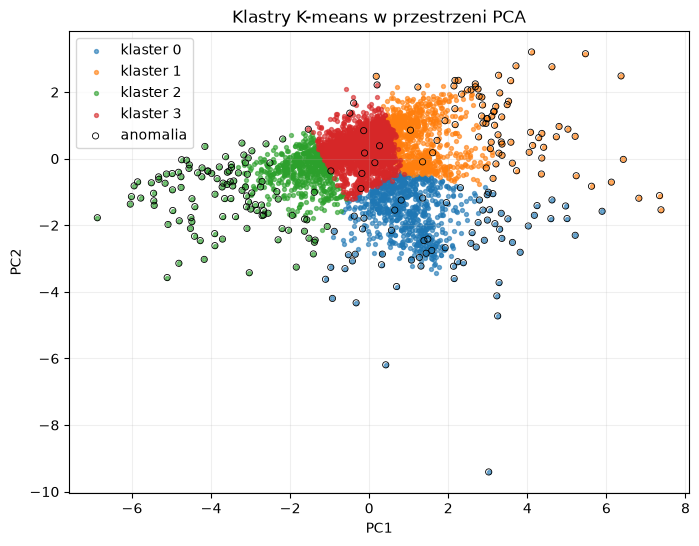

In [24]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Wyjaśniona wariancja PC1 + PC2:", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

plt.figure(figsize=(8, 6))
for c in sorted(df["cluster"].unique()):
    sel = (df["cluster"] == c).to_numpy()
    plt.scatter(X_pca[sel, 0], X_pca[sel, 1], s=8, alpha=0.6, label=f"klaster {c}")
anom = df["anomaly"].to_numpy()
plt.scatter(X_pca[anom, 0], X_pca[anom, 1],
            s=20, facecolors="none", edgecolors="black", linewidths=0.6, label="anomalia")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Klastry K-means w przestrzeni PCA")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Typowy przebieg w klastrach

Zamiast losowych pojedynczych szeregów pokazujemy **medianowy szereg** każdego klastra z pasmem 25–75 percentyla. Szeregi EGMS są odniesione do pierwszej akwizycji, więc można je porównywać bezpośrednio.

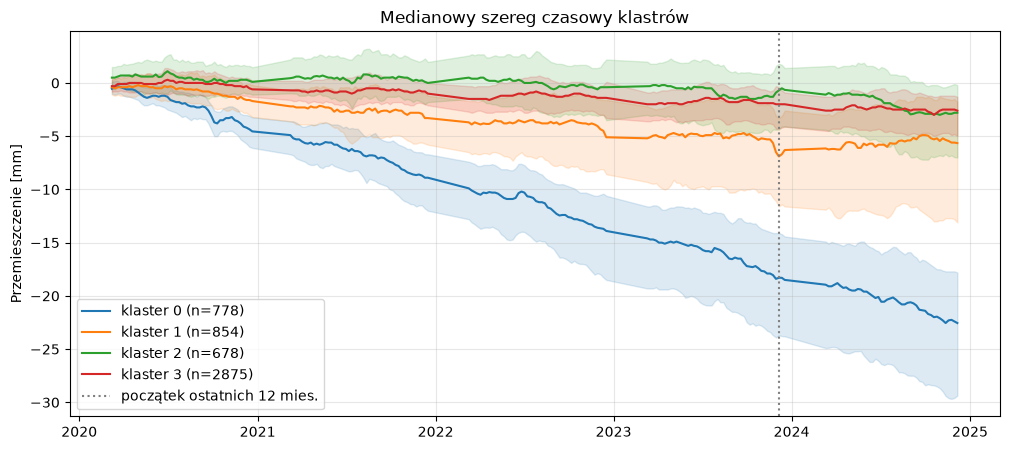

In [25]:
fig, ax = plt.subplots(figsize=(12, 5))

for c in sorted(df["cluster"].unique()):
    Y_c = Y[(df["cluster"] == c).to_numpy()]
    linia, = ax.plot(dates, np.median(Y_c, axis=0), label=f"klaster {c} (n={len(Y_c)})")
    ax.fill_between(dates, np.percentile(Y_c, 25, axis=0), np.percentile(Y_c, 75, axis=0),
                    color=linia.get_color(), alpha=0.15)

ax.axvline(recent_start, color="grey", linestyle=":", label="początek ostatnich 12 mies.")
ax.set_ylabel("Przemieszczenie [mm]")
ax.set_title("Medianowy szereg czasowy klastrów")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## Rozmieszczenie klastrów i anomalii

W wariancie pełnym obraz był zdominowany przez kopalnię. Teraz sprawdzamy, gdzie leżą anomalie i klastry poza nią. Szare punkty to PS usunięte z analizy.

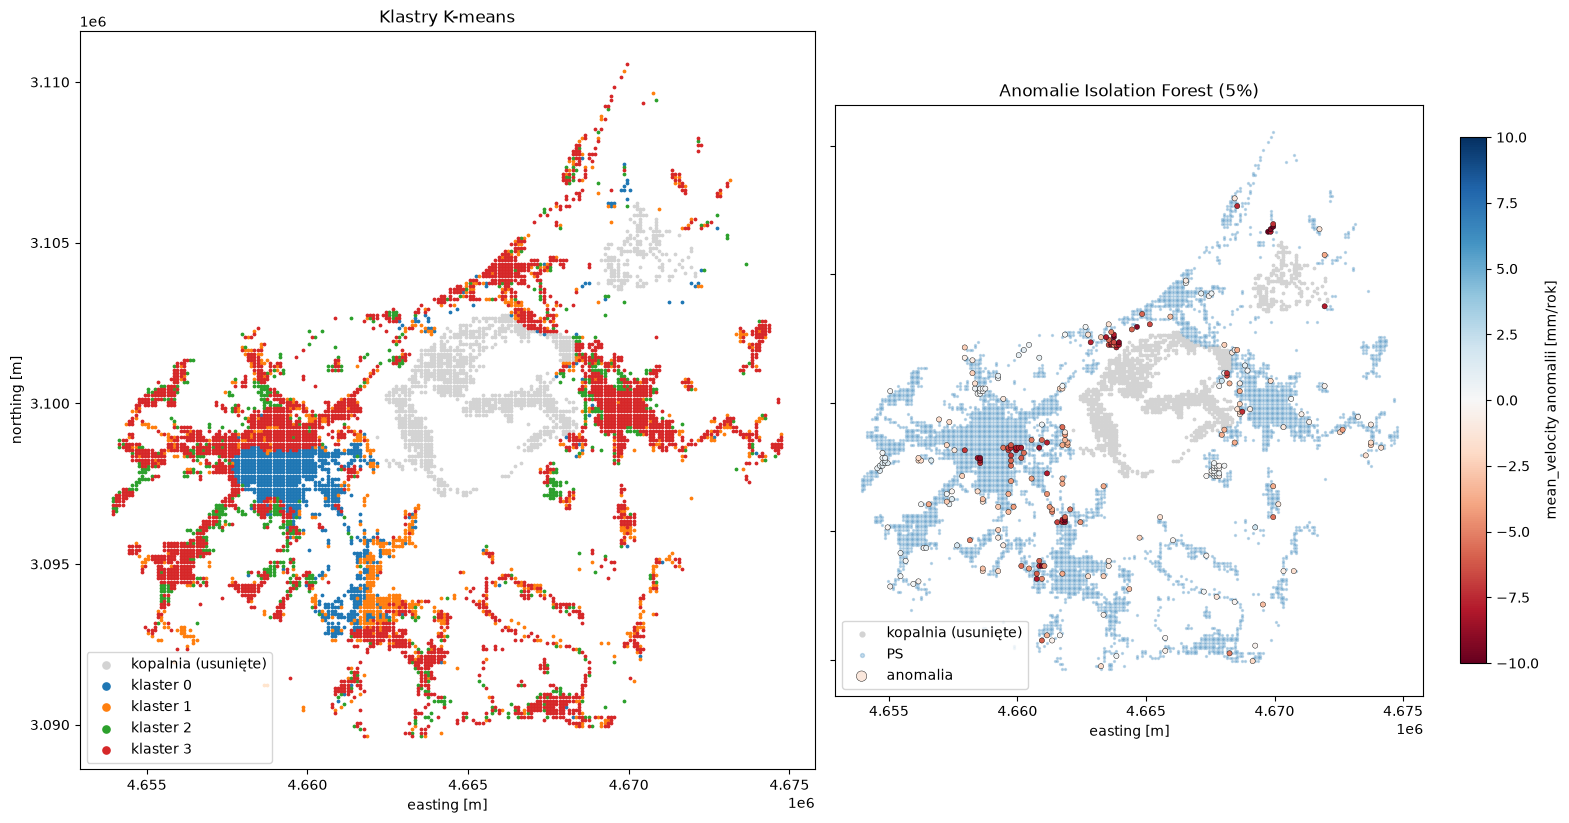

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)

usuniete = df_all[df_all["kopalnia"]]

for ax in axes:
    ax.scatter(usuniete["easting"], usuniete["northing"], s=3, color="lightgrey", label="kopalnia (usunięte)")
    ax.set_aspect("equal")
    ax.set_xlabel("easting [m]")

for c in sorted(df["cluster"].unique()):
    sel = df[df["cluster"] == c]
    axes[0].scatter(sel["easting"], sel["northing"], s=3, label=f"klaster {c}")
axes[0].set_ylabel("northing [m]")
axes[0].set_title("Klastry K-means")
axes[0].legend(loc="lower left", markerscale=3)

axes[1].scatter(df["easting"], df["northing"], s=2, color="tab:blue", alpha=0.25, label="PS")
anom = df[df["anomaly"]]
sc = axes[1].scatter(anom["easting"], anom["northing"], s=14, c=anom["mean_velocity"],
                     cmap="RdBu", vmin=-10, vmax=10, edgecolors="black", linewidths=0.3, label="anomalia")
plt.colorbar(sc, ax=axes[1], label="mean_velocity anomalii [mm/rok]", shrink=0.7)
axes[1].set_title("Anomalie Isolation Forest (5%)")
axes[1].legend(loc="lower left", markerscale=2)

plt.tight_layout()
plt.show()

# ETAP 6 — Porównanie z wariantem pełnym

Porównujemy tylko PS obecne w obu wariantach (punkty poza kopalnią).

In [27]:
por = df[["pid", "anomaly_score", "anomaly", "cluster", "mean_velocity", "trend_change", "rmse_ts"]].merge(
    wyniki_pelne[["pid", "anomaly_score", "anomaly", "cluster"]],
    on="pid",
    suffixes=("", "_pelny")
)

print("PS w porównaniu:", len(por))
print("Korelacja rangowa anomaly_score (Spearman):",
      round(por["anomaly_score"].corr(por["anomaly_score_pelny"], method="spearman"), 3))
print()
print("Anomalie wariantu pełnego:", wyniki_pelne["anomaly"].sum(),
      "– z tego poza kopalnią:", por["anomaly_pelny"].sum())
print("Anomalie bez kopalni:", por["anomaly"].sum())
print("  …wspólne z wariantem pełnym:", (por["anomaly"] & por["anomaly_pelny"]).sum())
print("  …nowe:", (por["anomaly"] & ~por["anomaly_pelny"]).sum())

PS w porównaniu: 5185
Korelacja rangowa anomaly_score (Spearman): 0.974

Anomalie wariantu pełnego: 314 – z tego poza kopalnią: 15
Anomalie bez kopalni: 260
  …wspólne z wariantem pełnym: 15
  …nowe: 245


In [28]:
# Klastry wariantu pełnego (wiersze) a klastry bez kopalni (kolumny)
pd.crosstab(
    por["cluster_pelny"],
    por["cluster"],
    rownames=["klaster (pełny)"],
    colnames=["klaster (bez kopalni)"],
    margins=True
)

klaster (bez kopalni),0,1,2,3,All
klaster (pełny),,,,,
0,114,0,678,656,1448
1,661,844,0,2219,3724
2,3,0,0,0,3
3,0,10,0,0,10
All,778,854,678,2875,5185


In [29]:
# Cechy anomalii: nowe a wspólne z wariantem pełnym
por["grupa"] = np.select(
    [por["anomaly"] & por["anomaly_pelny"], por["anomaly"], por["anomaly_pelny"]],
    ["wspólna", "nowa", "tylko w pełnym"],
    default="typowy PS"
)

por.groupby("grupa").agg(
    n_PS=("pid", "count"),
    mediana_velocity=("mean_velocity", "median"),
    mediana_trend_change=("trend_change", "median"),
    mediana_rmse=("rmse_ts", "median"),
    mediana_score=("anomaly_score", "median"),
).round(2)

,n_PS,mediana_velocity,mediana_trend_change,mediana_rmse,mediana_score
grupa,,,,,
nowa,245,-2.0,-1.57,2.3,0.6
typowy PS,4925,-0.7,0.06,0.9,0.4
wspólna,15,-0.5,-6.30,2.5,0.7


# ETAP 7 — Eksport do QGIS

Ten sam układ kolumn co w `EGMS_Turow_U_results.csv`, więc plik można bezpośrednio podstawić w `EGMS_buildings_analysis.ipynb` i `ryzyko_budynkow_wrazliwosc.ipynb`. Numery klastrów **nie odpowiadają** numerom z wariantu pełnego.

In [30]:
export_cols = [
    "pid", "easting", "northing",
    "mean_velocity", "acceleration", "seasonality", "rmse_ts",
    "trend", "trend_R2", "baseline_velocity", "recent_velocity", "trend_change",
    "anomaly_score", "anomaly", "cluster"
]

assert export_cols == list(wyniki_pelne.columns)

df[export_cols].to_csv("EGMS_Turow_bez_kopalni_U_results.csv", index=False)

print("Zapisano: EGMS_Turow_bez_kopalni_U_results.csv")
print("Liczba PS:", len(df))

Zapisano: EGMS_Turow_bez_kopalni_U_results.csv
Liczba PS: 5185


# Wnioski

## Maska kopalni

- Plik `EGMS_Turow_bez_kopalni_U.csv` zawiera 858 PS **odkrywki** (mediana −11 mm/rok), a nie punkty poza nią – został użyty jako maska.
- Maska z QGIS nie obejmowała zwałowiska zewnętrznego na północ od Bogatyni (ok. 145 PS, mediana ok. −36 mm/rok) ani fragmentu skarpy przy wschodniej krawędzi odkrywki. Strefy te wykryto automatycznie (zwarte strefy szybciej niż 10 mm/rok) i usunięto razem z buforem 300 m. Łącznie usunięto 1083 PS, do analizy zostało 5185 PS.
- Przy krawędzi odkrywki nie widać szerokiej strefy przyspieszonego osiadania – mediana prędkości już 100 m od maski nie różni się od reszty obszaru, dlatego nie stosowano bufora wokół całej odkrywki.

## Wpływ usunięcia kopalni na wyniki

- Rozkład cech zmienił się zasadniczo: odchylenie standardowe `mean_velocity` spadło z 9,8 do 1,8 mm/rok, a najszybsze osiadanie z −75 do ok. −21 mm/rok.
- **Anomalie:** z 314 anomalii wariantu pełnego tylko 15 leżało poza kopalnią. Bez kopalni wskazano 260 anomalii, z czego 245 to punkty nowe. Ranking `anomaly_score` w obrębie wspólnych PS prawie się nie zmienił (Spearman 0,97) – zmienił się przede wszystkim próg, który wcześniej wyznaczały punkty kopalni.
- Związek `anomaly_score` z RMSE szeregu osłabł (0,62 → 0,47), ale nadal ok. 60% anomalii ma `rmse_ts` > 2 mm. W TOP6 połowa to punkty systematycznego osiadania ok. −9 mm/rok, a połowa to szeregi o dużym szumie lub wyraźnej sezonowości, w których `trend_change` jest zawyżony przez cykl roczny w 12-miesięcznym oknie.
- **Klastry** mają teraz inny sens niż w wariancie pełnym (tam dwa z czterech klastrów opisywały kopalnię):
  - **klaster 0** (778 PS) – systematyczne, liniowe osiadanie ok. −4,7 mm/rok (ok. −22 mm w ciągu 5 lat); tworzy zwarte skupiska w **Zittau** oraz w **Hrádku nad Nisou**,
  - **klaster 1** (854 PS) – lekkie osiadanie (ok. −1,3 mm/rok) ze spowolnieniem w ostatnich 12 miesiącach (`trend_change` ok. +2,3),
  - **klaster 2** (678 PS) – punkty stabilne z przyspieszeniem w ostatnich 12 miesiącach (`trend_change` ok. −2,7),
  - **klaster 3** (2875 PS) – punkty stabilne.
- Klaster 0 jest przestrzennie zwarty i odpowiada realnemu zjawisku – osiadaniu w Zittau opisanemu też w `ryzyko_budynkow_wrazliwosc.ipynb`. Klastry 1 i 2 są rozproszone po całym obszarze i mają podwyższone RMSE, więc w dużej mierze opisują krótkookresową zmienność (szum, sezonowość) w ostatnim roku, a nie odrębne procesy.
- Anomalie skupiają się m.in. w Zittau, przy północnej i południowo-wschodniej krawędzi odkrywki oraz w Hrádku nad Nisou. Odsetek anomalii jest podobny w trzech krajach (CZ 3,7%, DE 4,8%, PL 6,2% PS przypisanych do budynków w promieniu 300 m).

## Ograniczenia

- Strefy zwałowiska i skarpy wyznaczono na podstawie prędkości, a nie obrysu z mapy. Usunięcie szybkich punktów automatycznie zmniejsza liczbę anomalii z dużą prędkością – dlatego usuwano tylko duże, zwarte strefy (≥ 10 PS), a pojedyncze szybkie punkty pozostawiono. Lepiej byłoby zastąpić tę część maski obrysem zwałowiska z QGIS.
- Pośredni wpływ kopalni (np. osiadanie w Zittau, prawdopodobnie związane z odwodnieniem) pozostaje w danych celowo – analiza nie rozstrzyga o jego przyczynie.
- `trend_change` liczony z 12-miesięcznego okna jest wrażliwy na sezonowość i przerwę zimową. Uwzględnienie sezonowości (np. dopasowanie trendu z członem rocznym) mogłoby ograniczyć liczbę anomalii wynikających z szumu.

## Dalsze kroki

- `EGMS_Turow_bez_kopalni_U_results.csv` ma ten sam układ kolumn co wyniki wariantu pełnego, więc można go użyć w `EGMS_buildings_analysis.ipynb` i `ryzyko_budynkow_wrazliwosc.ipynb` (wskaźnik ryzyka oparty na `anomaly_score` wyznaczonym bez kopalni).